In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print('libraries successfully loaded')

libraries successfully loaded


In [27]:
df = pd.read_csv('iris (1).txt', sep =',')
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [28]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [29]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
145    False
146    False
147    False
148    False
149    False
Length: 150, dtype: bool

In [30]:
df.duplicated().sum()

1

In [31]:
DF =df.drop_duplicates()

In [32]:
DF.info()

<class 'pandas.core.frame.DataFrame'>
Index: 149 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  149 non-null    float64
 1   sepal_width   149 non-null    float64
 2   petal_length  149 non-null    float64
 3   petal_width   149 non-null    float64
 4   species       149 non-null    object 
dtypes: float64(4), object(1)
memory usage: 7.0+ KB


In [33]:
DF.shape

(149, 5)

In [34]:
DF.describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,149.00,149.00,149.00,149.00
mean,5.84,3.06,3.75,1.19
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.30,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [35]:
DF['species'].unique()

array(['setosa', 'versicolor', 'virginica'], dtype=object)

In [36]:
DF['species'].value_counts()

species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64

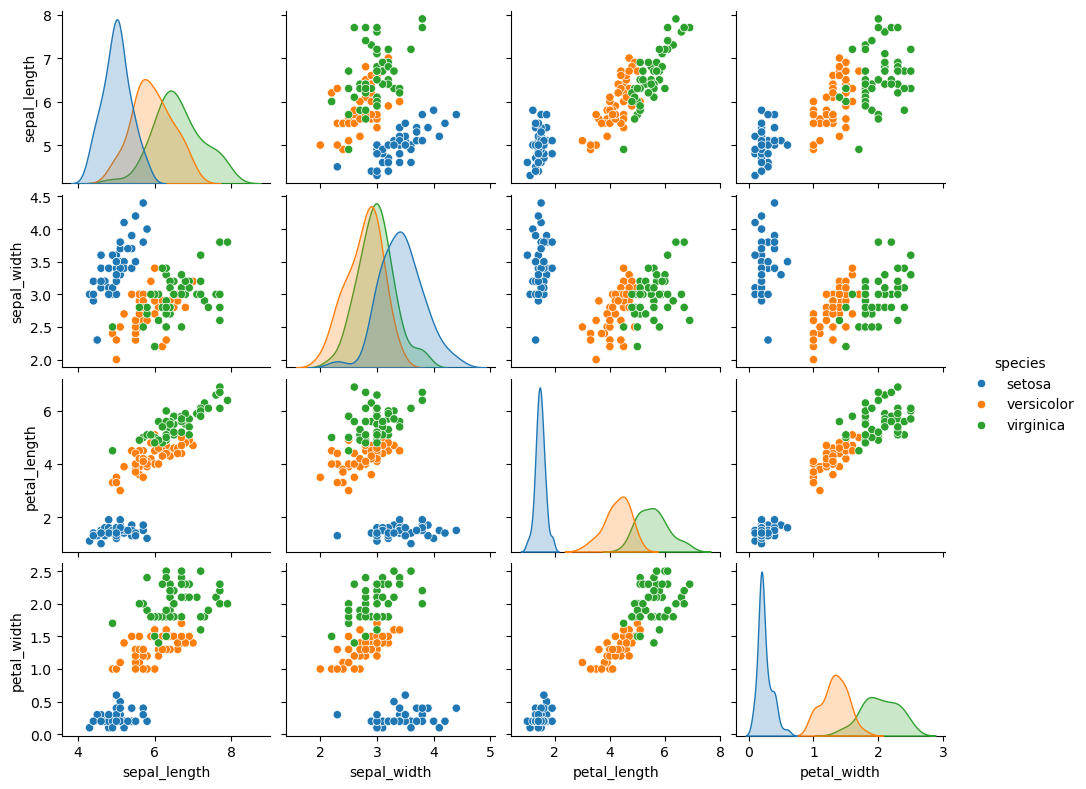

In [37]:
sns.pairplot(DF, hue = 'species', height = 2, aspect = 1.2)
plt.show()

In [38]:
x = DF.drop('species', axis =1)
y = DF['species']

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import(accuracy_score, classification_report, confusion_matrix)
print('fully loaded')

fully loaded


In [40]:
x_train, x_test, y_train, y_test = train_test_split (x,y,test_size = 0.30,random_state = 42, stratify = y)

In [41]:
scale = StandardScaler()
x_train = scale.fit_transform(x_train)
x_test = scale.transform(x_test)

In [42]:
logistic = LogisticRegression(random_state=42)
logistic.fit(x_train, y_train)
lg_pred = logistic.predict(x_test)
print('Accuracy:', accuracy_score(y_test,lg_pred))
print(confusion_matrix(y_test,lg_pred))
print(classification_report(y_test,lg_pred))

Accuracy: 0.9111111111111111
[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



In [43]:
decision = DecisionTreeClassifier(random_state=42)
decision.fit(x_train, y_train)
dc_pred = decision.predict(x_test)
print('Accuracy:', accuracy_score(y_test,dc_pred))
print(confusion_matrix(y_test,dc_pred))
print(classification_report(y_test,dc_pred))


Accuracy: 0.9111111111111111
[[15  0  0]
 [ 0 13  2]
 [ 0  2 13]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.87      0.87      0.87        15
   virginica       0.87      0.87      0.87        15

    accuracy                           0.91        45
   macro avg       0.91      0.91      0.91        45
weighted avg       0.91      0.91      0.91        45



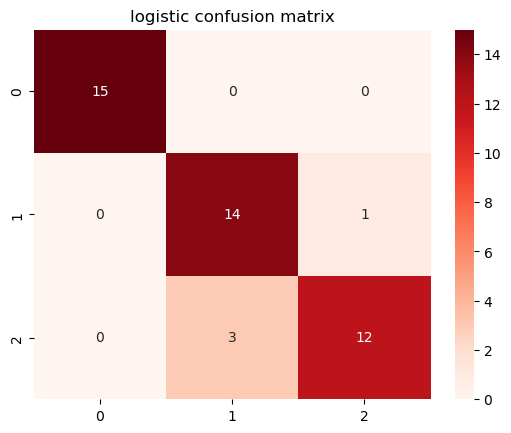

In [44]:
con_log = confusion_matrix(y_test, lg_pred)
sns.heatmap(con_log, annot =True, fmt = 'd', cmap = 'Reds')
plt.title('logistic confusion matrix')
plt.xlabel = ('predicted')
plt.ylabel =('actual')
plt.show()

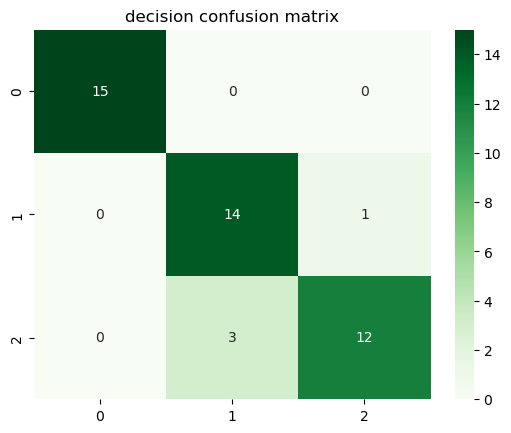

In [45]:
dec_log = confusion_matrix(y_test, lg_pred)
sns.heatmap(con_log, annot =True, fmt = 'd', cmap = 'Greens')
plt.title('decision confusion matrix')
plt.xlabel = ('predicted')
plt.ylabel =('actual')
plt.show()

In [46]:
from sklearn.inspection import DecisionBoundaryDisplay
print('loaded')

loaded


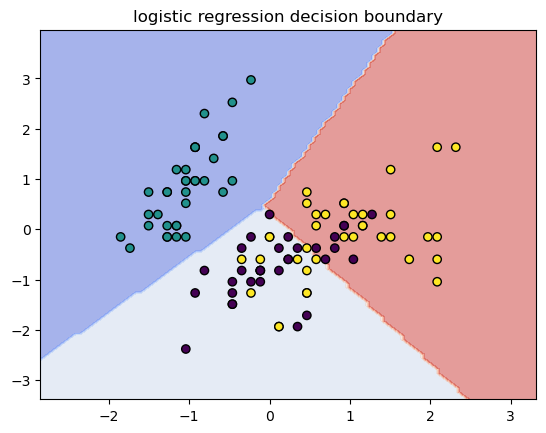

In [47]:
x_visual = x_train[:, :2]
visual =LogisticRegression(random_state=42)
visual.fit(x_visual, y_train)
DecisionBoundaryDisplay. from_estimator(visual, x_visual, response_method = 'predict',cmap = plt.cm.coolwarm, alpha = 0.5)
plt.scatter(x_visual[:,0],
            x_visual[:,1],c = pd.factorize(y_train)[0],edgecolors= 'black')
plt.title('logistic regression decision boundary')
plt.show()